# 2. An eco-bonus for electric bikes

Example of:

- the **Kalai-Smorodinsky (KS)** solution: the ideal point and the "same share of one's best hope";
- why Nash and KS agree on a simple split, and **disagree** as soon as the set $S$ is not a simple triangle;
- who really benefits from a **subsidy**, and why a price cap matters;
- how **risk aversion** weakens a negotiator.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from bargain import *

## 2.1 The deal without bonus

A bike shop sells an electric bike in a small city model of a country where the price for a E-bike is very low. 

| Assumption | Value |
|---|---|
| seller's cost (reservation price) | 60 EUR (`COST`) |
| value of the bike for the buyer | 100 EUR (`VALUE`) |
| price $p$ | between 60 and 100 EUR |
| gains | seller $u_1 = p - 60$, buyer $u_2 = 100 - p$; no sale: $d = (0, 0)$ |

`bike_prices()` gives all the possible prices and `bike_deal(prices)` the corresponding gains.

In [5]:
#we can define (in fact it is already done in the bargain library) the following constants for the bike problem
COST = 60       # EUR: the seller's cost (reservation price)
VALUE = 100     # EUR: what the bike is worth to the buyer
CAP = 100       # EUR: maximum price allowed (price cap)

In [7]:
# bike_prices(bonus=0, cap=CAP, cost=COST, value=VALUE, n=4001)  returns an array of all the possible prices for the bike:
# from the minimal price (the seller's cost) 
# to the maximum price (the minimum of the cap and the buyer's value plus bonus), 
# for example, if the bonus is 10, and the bike worth 100 for the user, the maximum price is 100 + 10 = 110, but the cap is 100, so the maximum price is 100.
# because (1) the seller cannot sell the bike for more than the cap (limit to have the bonus), 
# and (2) the buyer should have to pay 100 to have later 10 back from the state, and may be he/she cannon afford 110
#exampe of use
some_prices = bike_prices(n=9)
print("some prices for the bike:", some_prices)

some prices for the bike: [ 60.  65.  70.  75.  80.  85.  90.  95. 100.]


In [12]:
# def bike_deal(price, bonus=0, cost=COST, value=VALUE) take an array of prices and returns the corresponding array of gains 
# for the seller (price - cost) and the buyer (value - price + bonus)
some_gains = bike_deal(some_prices)
for i in range(len(some_prices)):
    print(f"price {some_prices[i]:.2f}: gains for the seller={some_gains[i][0]:.2f} and the buyer={some_gains[i][1]:.2f} ")

price 60.00: gains for the seller=0.00 and the buyer=40.00 
price 65.00: gains for the seller=5.00 and the buyer=35.00 
price 70.00: gains for the seller=10.00 and the buyer=30.00 
price 75.00: gains for the seller=15.00 and the buyer=25.00 
price 80.00: gains for the seller=20.00 and the buyer=20.00 
price 85.00: gains for the seller=25.00 and the buyer=15.00 
price 90.00: gains for the seller=30.00 and the buyer=10.00 
price 95.00: gains for the seller=35.00 and the buyer=5.00 
price 100.00: gains for the seller=40.00 and the buyer=0.00 


**Exercise 1**.
Build $S$, the set of solution (gain for seller, gain for buyer)  
Compute the Nash solution and the KS solution (call `ks_solution(S)`), and the corresponding prices.  
Draw them with `plot_problem(S, solutions={"Nash": nash, "KS": ks}, line=True, title="No bonus");`.

In [2]:
# Exercise 1: your code here

Nash: [20. 20.] -> price 80.0 | KS: [20. 20.] -> price 80.0


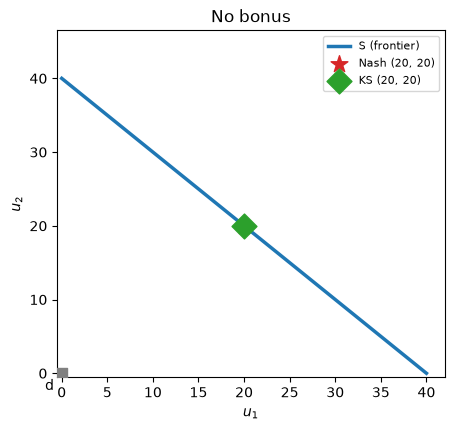

In [ ]:

plot_problem(S, solutions={"Nash": nash, "KS": ks}, line=True, title="No bonus");

**Reading.** Both give $(20, 20)$, i.e. a price of 80 EUR. On a simple split (a frontier from one axis to the other), Nash and KS agree.

---

## 2.2 The ideal point

KS starts from the **ideal point** $a = (a_1, a_2)$: $a_i$ is the best agent $i$ can hope for, while the other still accepts (gets at least $d_j$).  
Here the seller can hope for $p = 100$ ($a_1 = 40$) and the buyer for $p = 60$ ($a_2 = 40$).

KS then chooses the agreement where **each one gets the same share of its best hope**:  
$\frac{u_1 - d_1}{a_1 - d_1} = \frac{u_2 - d_2}{a_2 - d_2}$  
Geometrically: the point of the frontier on the segment $[d, a]$.

ideal point a = [40. 40.]


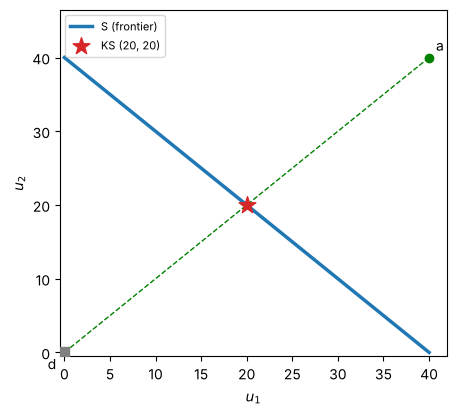

In [4]:
print("ideal point a =", ideal_point(S))
ax = plot_problem(S, solutions={"KS": ks_solution(S)}, line=True)
a = ideal_point(S)
ax.plot([0, a[0]], [0, a[1]], "g--", lw=1); ax.scatter(*a, color="g"); ax.annotate("a", a, xytext=(5, 5), textcoords="offset points");

## 2.3 An eco-bonus of 10 EUR, with a price cap

The State now pays a **bonus of 10 EUR to the buyer**, and the price stays **capped at 100 EUR** (`CAP`).

- at the same price, the seller gains the same and the buyer gains 10 EUR more: $u_2 = 110 - p$;
- the frontier moves up ($u_1 + u_2 = 50$) but the seller's best hope does not change ($a_1 = 40$, because of the cap).

The set $S$ has grown **in favour of the buyer only**. The **monotonicity** axiom of KS says: the buyer must not get less than before (20).

**Exercise 2**   
With `bike_prices(bonus=10)` and `bike_deal(prices, bonus=10)`, compute the ideal point, the Nash and KS solutions, and the prices.   
Draw them.

In [5]:
# Exercise 2: your code here

ideal point: [40. 50.]
Nash: [25. 25.] -> price 85.00
KS: [22.22 27.78] -> price 82.22


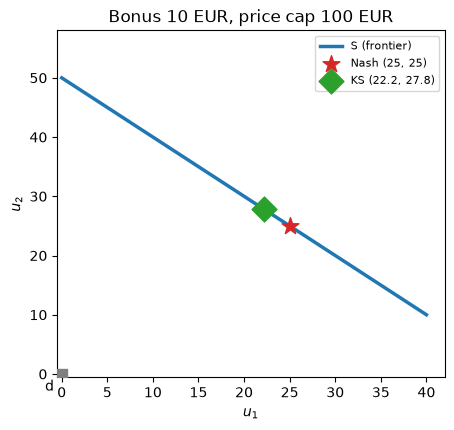

In [ ]:

plot_problem(S10, solutions={"Nash": nash10, "KS": ks10}, line=True, title="Bonus 10 EUR, price cap 100 EUR");

**Reading.**   
Nash: $(25, 25)$, price 85 EUR. KS: $(22.2, 27.8)$, price about 82 EUR.  
Both respect monotonicity here (the buyer goes from 20 to 25 or 27.8), but they **share the bonus differently**:  
with Nash the seller raises its price by 5 EUR and takes **half** of the bonus;   
with KS it takes only about 22 %.

---

## 2.4 Who captures the subsidy?

**Exercise 3**  
For bonuses from 1 to 40 EUR, compute the share of the bonus captured by the seller, $\frac{p^*(\text{bonus}) - 80}{\text{bonus}}$, with Nash and with KS.   
Do it twice: with the price cap (`cap=CAP`) and without (`cap=np.inf`). 
Plot the four curves.

In [7]:
# Exercise 3: your code here

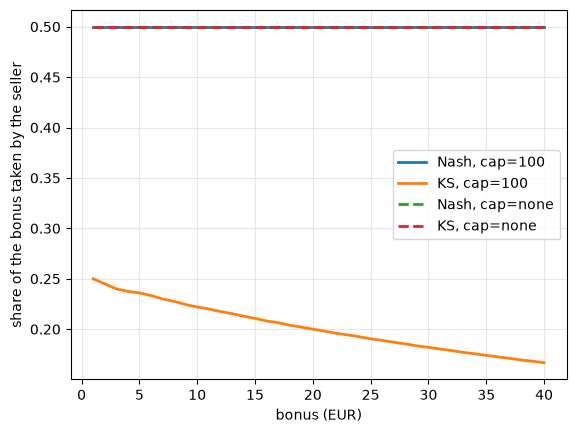

In [ ]:
bonuses = np.arange(1, 41)


**Reading.**

- **Without a cap**, the bonus simply enlarges the surplus: $S$ is again a simple split, and Nash and KS both give **half** of the bonus to the seller.
- **With the cap**, the seller cannot ask more than 100 EUR: its best hope $a_1$ stays at 40. Nash still gives it half of the bonus (until the cap is reached), but KS gives it less and less ($\frac{20}{80 + \text{bonus}}$).

The rule used to "split fairly" changes **who benefits from public money**. This is the message of the slide: the choice of axioms is a choice of fairness.

---

## 2.5 A risk-averse buyer

*Utility $\neq$ money.*  
Suppose the buyer is **risk-averse**: a gain of $g$ EUR is worth $\sqrt{g}$ to him (the nb of remaining bike is very low, there is a risk to not buy one).   
The seller stays risk-neutral. No bonus here.

$S$ is now the set of pairs $(p - 60,\ \sqrt{100 - p})$.

**Exercise 4**   
Build this new $S$.  
Compute the Nash and KS solutions **in utilities**, and   
translate them back into prices and euros for the buyer.

In [9]:
# Exercise 4: your code here

Nash: utilities [26.67  3.65] -> price 86.67 EUR, buyer gains 13.33 EUR
KS: utilities [24.72  3.91] -> price 84.72 EUR, buyer gains 15.28 EUR


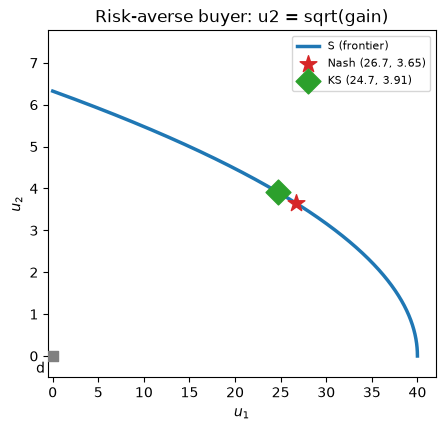

In [ ]:

plot_problem(S_risk, solutions={"Nash": nash_solution(S_risk), "KS": ks_solution(S_risk)}, line=True,
             title="Risk-averse buyer: u2 = sqrt(gain)");

**Reading.**   
With Nash, the price goes up to about 86.7 EUR: the buyer keeps only a **third** of the 40 EUR surplus (13.3 EUR), against half before.  
The risk to miss the bike frightens the risk-averse agent, so he accepts a smaller share:  
**risk aversion weakens bargaining power**.  
KS is a little kinder to him (about 15.3 EUR).

---
## Key points

| Situation | Nash | KS |
|---|---|---|
| no bonus (simple split) | price 80 | price 80 |
| bonus 10 EUR, cap 100 EUR | price 85: seller takes 50 % of the bonus | price ≈ 82: seller takes ≈ 22 % |
| bonus without cap | 50 % to the seller | 50 % to the seller |
| risk-averse buyer | buyer gets 1/3 of the surplus | buyer gets ≈ 38 % |

- Nash: maximise the product of the gains; KS: same share of one's best hope (ideal point $a$).
- KS satisfies **monotonicity** (if $S$ grows in favour of one agent only, this agent does not lose); Nash satisfies IIA.
- A price cap changes the shape of $S$, hence who captures a subsidy.